# Selección del umbral de derivación mediante Pareto y Kneedle — CROHME 2014

Este notebook selecciona la configuración de derivación de la cascada **SANv2 → PosFormer** sobre CROHME 2014. Utiliza las puntuaciones conjuntas de símbolos y relaciones estructurales calculadas previamente para Chow-Sum, Chow-Average y Chow-Quantile-0.

Para cada medida se evalúan los percentiles 1–99 de su distribución y los dos extremos: aceptar todas las expresiones con SANv2 y derivarlas todas a PosFormer. Cada configuración $c=(k,t)$ se caracteriza por su ExpRate, tiempo promedio estimado y tasa de escalamiento. Después se obtiene la frontera de Pareto global y se selecciona un punto de rodilla con la formulación normalizada de Kneedle.

> CROHME 2014 se usa aquí como conjunto de experimentación y selección. La evaluación posterior de la configuración elegida debe realizarse en CROHME 2016 y 2019.

## Definición de la cascada

Como las tres puntuaciones son sumas, promedios o mínimos de $\log p$, una puntuación mayor (más cercana a cero) indica mayor confianza. Para una medida $k$ y umbral $t$:

- SANv2 se acepta si $s_k(x) \ge t$.
- La expresión se deriva a PosFormer si $s_k(x) < t$.

El acierto final por muestra es el de SANv2 cuando se acepta y el de PosFormer cuando se deriva. El tiempo estimado incluye siempre SANv2, porque su confianza decide el enrutamiento, y añade PosFormer únicamente para las muestras derivadas:

$$T_c(x)=T_{SANv2}(x)+\mathbb{1}[s_k(x)<t]T_{PosFormer}(x).$$

Los tiempos proceden de ejecuciones ya registradas y se emplean como estimación comparativa; no sustituyen un benchmark dedicado de la cascada completa.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.interpolate import UnivariateSpline

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)
plt.style.use('seaborn-v0_8-whitegrid')

METRICS = {
    'final_chow_sum': 'Chow-Sum',
    'final_chow_average': 'Chow-Average',
    'final_chow_quantile_0': 'Chow-Quantile-0',
}
PERCENTILES = np.arange(1, 100, dtype=int)
EXPECTED_SAMPLES = 986
KNEEDLE_S_VALUES = (0.0, 0.5, 1.0, 2.0, 3.0, 5.0)
KNEEDLE_REFERENCE_S = 1.0
KNEEDLE_SPLINE_S_VALUES = (0.0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2)
KNEEDLE_REFERENCE_SPLINE_S = 1e-4


## Localización de entradas y salidas

La búsqueda de la raíz hace que el notebook funcione tanto si Jupyter se inicia en la raíz del proyecto como si se inicia en `Cascada/03_analisis`, incluyendo la ruta montada por WSL2.

In [2]:
def find_project_root(start=Path.cwd()):
    required = Path('Cascada/03_analisis/resultados/confianza_conjunta_sanv2_crohme_2014.csv')
    for candidate in (start, *start.parents):
        if (candidate / required).is_file():
            return candidate.resolve()
    raise FileNotFoundError(
        'No se encontró la raíz del proyecto. Abra en VS Code la carpeta Programas y vuelva a ejecutar.'
    )

PROJECT_ROOT = find_project_root()
ANALYSIS_DIR = PROJECT_ROOT / 'Cascada' / '03_analisis'
RESULTS_DIR = ANALYSIS_DIR / 'resultados'
CONFIDENCE_PATH = RESULTS_DIR / 'confianza_conjunta_sanv2_crohme_2014.csv'
COMPARISON_PATH = (
    PROJECT_ROOT / 'Cascada' / '01_seleccion' / 'resultados' /
    'comparacion_san_posformer_crohme_2014.csv'
)

OUTPUT_CONFIGS = RESULTS_DIR / 'configuraciones_derivacion_crohme_2014.csv'
OUTPUT_PARETO = RESULTS_DIR / 'frontera_pareto_derivacion_crohme_2014.csv'
OUTPUT_KNEE = RESULTS_DIR / 'configuracion_kneedle_crohme_2014.csv'
OUTPUT_KNEEDLE_CANDIDATES = RESULTS_DIR / 'candidatos_kneedle_spline_s_sensibilidad_crohme_2014.csv'
OUTPUT_KNEEDLE_GRID = RESULTS_DIR / 'resultados_kneedle_spline_s_sensibilidad_crohme_2014.csv'
OUTPUT_SUMMARY = RESULTS_DIR / 'resumen_seleccion_derivacion_crohme_2014.json'
OUTPUT_PARETO_FIG = RESULTS_DIR / 'pareto_kneedle_derivacion_crohme_2014.png'
OUTPUT_KNEEDLE_DIAGNOSTIC_FIG = RESULTS_DIR / 'diagnostico_kneedle_normalizado_crohme_2014.png'
OUTPUT_KNEEDLE_SENSITIVITY_FIG = RESULTS_DIR / 'sensibilidad_kneedle_s_crohme_2014.png'
OUTPUT_RATES_FIG = RESULTS_DIR / 'exprate_escalamiento_derivacion_crohme_2014.png'
OUTPUT_TIME_PERCENTILE_FIG = RESULTS_DIR / 'tiempo_percentil_derivacion_crohme_2014.png'
OUTPUT_STABILITY_FIG = RESULTS_DIR / 'estabilidad_local_kneedle_crohme_2014.png'
OUTPUT_GAIN_LOSS_FIG = RESULTS_DIR / 'ganancias_perdidas_derivacion_crohme_2014.png'
OUTPUT_COMPOSITION_FIG = RESULTS_DIR / 'composicion_resultados_derivacion_crohme_2014.png'
OUTPUT_MARGINAL_FIG = RESULTS_DIR / 'costo_marginal_pareto_crohme_2014.png'

print('Raíz del proyecto:', PROJECT_ROOT)
print('Confianza conjunta:', CONFIDENCE_PATH)
print('Comparación SAN–PosFormer:', COMPARISON_PATH)


Raíz del proyecto: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas
Confianza conjunta: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/confianza_conjunta_sanv2_crohme_2014.csv
Comparación SAN–PosFormer: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/comparacion_san_posformer_crohme_2014.csv


## Carga, alineación y validación

Los archivos se unen uno a uno mediante `sample_id`. Se exige que el estado de acierto común normalizado de SANv2 coincida en ambos resultados, evitando mezclar protocolos de evaluación diferentes.

In [3]:
confidence_raw = pd.read_csv(CONFIDENCE_PATH)
comparison_raw = pd.read_csv(COMPARISON_PATH)

confidence_columns = [
    'sample_id', 'status', 'correct_common_normalized', 'inference_time_ms',
    *METRICS.keys(),
]
comparison_columns = [
    'sample_id', 'status', 'san_common_correct', 'posformer_common_correct',
    'posformer_time_ms',
]

missing_confidence = sorted(set(confidence_columns) - set(confidence_raw.columns))
missing_comparison = sorted(set(comparison_columns) - set(comparison_raw.columns))
if missing_confidence or missing_comparison:
    raise KeyError(
        f'Columnas faltantes. Confianza: {missing_confidence}; comparación: {missing_comparison}'
    )

confidence = confidence_raw.loc[confidence_raw['status'].eq('ok'), confidence_columns].copy()
comparison = comparison_raw.loc[comparison_raw['status'].eq('ok'), comparison_columns].copy()

if confidence['sample_id'].duplicated().any() or comparison['sample_id'].duplicated().any():
    raise ValueError('Los archivos contienen sample_id duplicados.')

data = confidence.merge(
    comparison.drop(columns='status'),
    on='sample_id',
    how='inner',
    validate='one_to_one',
).rename(columns={
    'inference_time_ms': 'sanv2_time_ms',
    'correct_common_normalized': 'sanv2_correct',
    'posformer_common_correct': 'posformer_correct',
})

if len(data) != EXPECTED_SAMPLES:
    raise ValueError(f'Se esperaban {EXPECTED_SAMPLES} muestras alineadas y se obtuvieron {len(data)}.')
if not np.array_equal(data['sanv2_correct'].to_numpy(), data['san_common_correct'].to_numpy()):
    raise ValueError('El acierto de SANv2 no coincide entre los dos archivos.')

numeric_columns = [
    'sanv2_time_ms', 'posformer_time_ms', 'sanv2_correct', 'posformer_correct',
    *METRICS.keys(),
]
if not np.isfinite(data[numeric_columns].to_numpy(dtype=float)).all():
    raise ValueError('Hay valores no finitos en las columnas necesarias.')
if (data[['sanv2_time_ms', 'posformer_time_ms']] < 0).any().any():
    raise ValueError('Se encontraron tiempos de inferencia negativos.')

baseline = pd.DataFrame({
    'sistema': ['SANv2', 'PosFormer'],
    'aciertos': [int(data['sanv2_correct'].sum()), int(data['posformer_correct'].sum())],
    'ExpRate (%)': [100 * data['sanv2_correct'].mean(), 100 * data['posformer_correct'].mean()],
    'tiempo medio individual (ms)': [data['sanv2_time_ms'].mean(), data['posformer_time_ms'].mean()],
})
display(baseline.style.format({'ExpRate (%)': '{:.2f}', 'tiempo medio individual (ms)': '{:.2f}'}))


,sistema,aciertos,ExpRate (%),tiempo medio individual (ms)
0,SANv2,560,56.80,106.95
1,PosFormer,618,62.68,364.24


## Generación y evaluación de los 303 candidatos

Cada medidor aporta 101 configuraciones: 99 umbrales percentiles, aceptación total y derivación total. Los percentiles se conservan aunque dos de ellos produzcan el mismo valor por la presencia de empates; esto mantiene explícito el protocolo de búsqueda especificado.

In [4]:
def evaluate_configuration(frame, metric, metric_label, policy, threshold, percentile=np.nan):
    if policy == 'accept_all':
        accept_sanv2 = np.ones(len(frame), dtype=bool)
    elif policy == 'escalate_all':
        accept_sanv2 = np.zeros(len(frame), dtype=bool)
    elif policy == 'percentile':
        accept_sanv2 = frame[metric].to_numpy() >= threshold
    else:
        raise ValueError(f'Política desconocida: {policy}')

    escalate = ~accept_sanv2
    cascade_correct = np.where(
        accept_sanv2,
        frame['sanv2_correct'].to_numpy(dtype=int),
        frame['posformer_correct'].to_numpy(dtype=int),
    )
    cascade_time_ms = (
        frame['sanv2_time_ms'].to_numpy(dtype=float)
        + escalate * frame['posformer_time_ms'].to_numpy(dtype=float)
    )
    sanv2_correct = frame['sanv2_correct'].to_numpy(dtype=bool)
    posformer_correct = frame['posformer_correct'].to_numpy(dtype=bool)
    recovered = escalate & ~sanv2_correct & posformer_correct
    lost = escalate & sanv2_correct & ~posformer_correct
    accepted_correct = accept_sanv2 & sanv2_correct
    accepted_wrong = accept_sanv2 & ~sanv2_correct
    escalated_correct = escalate & posformer_correct
    escalated_wrong = escalate & ~posformer_correct

    return {
        'metric': metric,
        'metric_label': metric_label,
        'policy': policy,
        'percentile': percentile,
        'threshold': threshold,
        'accepted_count': int(accept_sanv2.sum()),
        'escalated_count': int(escalate.sum()),
        'acceptance_rate': float(accept_sanv2.mean()),
        'escalation_rate': float(escalate.mean()),
        'correct_count': int(cascade_correct.sum()),
        'exprate': float(cascade_correct.mean()),
        'average_time_ms': float(cascade_time_ms.mean()),
        'total_time_s': float(cascade_time_ms.sum() / 1000),
        'recovered_count': int(recovered.sum()),
        'lost_count': int(lost.sum()),
        'net_gain_count': int(recovered.sum() - lost.sum()),
        'accepted_correct_count': int(accepted_correct.sum()),
        'accepted_wrong_count': int(accepted_wrong.sum()),
        'escalated_correct_count': int(escalated_correct.sum()),
        'escalated_wrong_count': int(escalated_wrong.sum()),
    }

records = []
for metric, metric_label in METRICS.items():
    scores = data[metric].to_numpy(dtype=float)
    records.append(evaluate_configuration(
        data, metric, metric_label, 'accept_all', -np.inf
    ))
    for percentile in PERCENTILES:
        threshold = float(np.quantile(scores, percentile / 100, method='linear'))
        records.append(evaluate_configuration(
            data, metric, metric_label, 'percentile', threshold, int(percentile)
        ))
    records.append(evaluate_configuration(
        data, metric, metric_label, 'escalate_all', np.inf
    ))

configurations = pd.DataFrame.from_records(records)
configurations.insert(0, 'configuration_id', [f'c{i:03d}' for i in range(1, len(configurations) + 1)])
configurations['exprate_percent'] = 100 * configurations['exprate']
configurations['escalation_rate_percent'] = 100 * configurations['escalation_rate']
configurations['gain_over_sanv2_pp'] = (
    configurations['exprate'] - data['sanv2_correct'].mean()
) * 100

assert len(configurations) == len(METRICS) * 101
display(
    configurations.groupby('metric_label', sort=False)
    .agg(
        configuraciones=('configuration_id', 'size'),
        exprate_min=('exprate_percent', 'min'),
        exprate_max=('exprate_percent', 'max'),
        tiempo_min_ms=('average_time_ms', 'min'),
        tiempo_max_ms=('average_time_ms', 'max'),
    )
    .style.format('{:.3f}')
)


,configuraciones,exprate_min,exprate_max,tiempo_min_ms,tiempo_max_ms
metric_label,,,,,
Chow-Sum,101.000,56.795,62.779,106.954,471.192
Chow-Average,101.000,56.795,62.982,106.954,471.192
Chow-Quantile-0,101.000,56.795,62.982,106.954,471.192


## Frontera de Pareto

Una configuración queda dominada si existe otra con ExpRate mayor o igual y tiempo menor o igual, con al menos una mejora estricta. La comparación se realiza globalmente entre los tres medidores y todos sus umbrales. Las configuraciones con objetivos idénticos se conservan como alternativas equivalentes.

In [5]:
def nondominated_mask(frame, time_column='average_time_ms', accuracy_column='exprate'):
    times = frame[time_column].to_numpy(dtype=float)
    accuracies = frame[accuracy_column].to_numpy(dtype=float)
    keep = np.ones(len(frame), dtype=bool)
    for i in range(len(frame)):
        no_worse = (times <= times[i]) & (accuracies >= accuracies[i])
        strictly_better = (times < times[i]) | (accuracies > accuracies[i])
        keep[i] = not np.any(no_worse & strictly_better)
    return keep

configurations['is_pareto'] = nondominated_mask(configurations)
pareto = (
    configurations.loc[configurations['is_pareto']]
    .sort_values(['average_time_ms', 'exprate', 'metric_label', 'percentile'], na_position='first')
    .reset_index(drop=True)
)

pareto_display_columns = [
    'configuration_id', 'metric_label', 'policy', 'percentile', 'threshold',
    'exprate_percent', 'average_time_ms', 'escalation_rate_percent',
]
print(f'Configuraciones no dominadas: {len(pareto)} de {len(configurations)}')
display(pareto[pareto_display_columns].style.format({
    'percentile': '{:.0f}', 'threshold': '{:.8f}', 'exprate_percent': '{:.3f}',
    'average_time_ms': '{:.3f}', 'escalation_rate_percent': '{:.2f}',
}, na_rep='—'))


Configuraciones no dominadas: 40 de 303


,configuration_id,metric_label,policy,percentile,threshold,exprate_percent,average_time_ms,escalation_rate_percent
0,c102,Chow-Average,accept_all,—,-inf,56.795,106.954,0.00
1,c203,Chow-Quantile-0,accept_all,—,-inf,56.795,106.954,0.00
2,c001,Chow-Sum,accept_all,—,-inf,56.795,106.954,0.00
3,c104,Chow-Average,percentile,2,-0.34361278,56.897,110.913,2.03
4,c105,Chow-Average,percentile,3,-0.27868089,57.099,115.808,3.04
5,c106,Chow-Average,percentile,4,-0.24579947,57.201,119.932,4.06
6,c108,Chow-Average,percentile,6,-0.20109306,57.302,126.232,6.09
7,c109,Chow-Average,percentile,7,-0.18286971,57.404,129.126,7.00
8,c110,Chow-Average,percentile,8,-0.17153296,57.809,132.543,8.01
9,c111,Chow-Average,percentile,9,-0.15646253,57.911,135.445,9.03


## Punto de rodilla con Kneedle

Se colapsan los puntos de objetivo repetidos y se ordena la frontera por tiempo. El ExpRate se suaviza mediante `UnivariateSpline` y después se normalizan tiempo y ExpRate suavizado al intervalo $[0,1]$ para calcular

$$d(x)=y_{norm}(x)-x_{norm}.$$

En `UnivariateSpline`, $s$ limita aproximadamente la suma ponderada de residuos cuadrados del ajuste: $s=0$ interpola exactamente los puntos y valores mayores permiten una curva más suave. No debe confundirse este $s$ minúsculo con la sensibilidad $S$ de Kneedle.

Los máximos locales de $d(x)$ son candidatos. Se prueba la cuadrícula formada por $s\in\{0,10^{-6},10^{-5},10^{-4},10^{-3},10^{-2}\}$ para el spline y $S\in\{0,0.5,1,2,3,5\}$ para la sensibilidad. En cada combinación se calcula el umbral adaptativo $T_i=d_i-S\,\overline{\Delta x}$. Un candidato se confirma si la curva cae por debajo de su umbral antes del siguiente máximo local; se descarta si alcanza un mínimo local y vuelve a subir antes del cruce. Se reportan las 36 combinaciones y todos sus candidatos. Como referencia operativa se usa provisionalmente $s=10^{-4}$ y $S=1$; si hubiera varios knees confirmados, se toma el de mayor diferencia normalizada.

In [6]:
def prepare_kneedle_curve(pareto_frame, spline_s):
    objective = (
        pareto_frame[['average_time_ms', 'exprate']]
        .drop_duplicates()
        .sort_values(['average_time_ms', 'exprate'])
        .reset_index(drop=True)
    )
    if len(objective) < 3:
        raise ValueError('Kneedle requiere al menos tres puntos de objetivo no dominados.')

    objective['exprate_original'] = objective['exprate']
    x = objective['average_time_ms'].to_numpy(dtype=float)
    y_original = objective['exprate_original'].to_numpy(dtype=float)
    x_for_spline = (x - x.min()) / (x.max() - x.min())
    spline = UnivariateSpline(
        x_for_spline, y_original, k=min(3, len(objective) - 1), s=float(spline_s)
    )
    objective['exprate_smoothed'] = spline(x_for_spline)
    objective['spline_s'] = float(spline_s)
    y_smoothed = objective['exprate_smoothed'].to_numpy(dtype=float)
    x_span = x.max() - x.min()
    y_original_span = y_original.max() - y_original.min()
    y_smoothed_span = y_smoothed.max() - y_smoothed.min()
    if x_span <= 0 or y_original_span <= 0 or y_smoothed_span <= 0:
        raise ValueError('La frontera no tiene variación suficiente para aplicar Kneedle.')

    objective['time_normalized'] = (x - x.min()) / x_span
    objective['exprate_original_normalized'] = (
        (y_original - y_original.min()) / y_original_span
    )
    objective['exprate_normalized'] = (
        (y_smoothed - y_smoothed.min()) / y_smoothed_span
    )
    objective['kneedle_difference'] = (
        objective['exprate_normalized'] - objective['time_normalized']
    )

    difference = objective['kneedle_difference'].to_numpy(dtype=float)
    local_maximum = np.zeros(len(objective), dtype=bool)
    local_minimum = np.zeros(len(objective), dtype=bool)
    for index in range(1, len(objective) - 1):
        local_maximum[index] = (
            difference[index - 1] < difference[index]
            and difference[index + 1] < difference[index]
        )
        local_minimum[index] = (
            difference[index - 1] > difference[index]
            and difference[index + 1] > difference[index]
        )
    objective['is_local_maximum'] = local_maximum
    objective['is_local_minimum'] = local_minimum
    if not local_maximum.any():
        raise RuntimeError('La curva de diferencias suavizada no contiene máximos locales.')
    return objective


def evaluate_kneedle_s(curve, spline_s, sensitivity):
    x_normalized = curve['time_normalized'].to_numpy(dtype=float)
    difference = curve['kneedle_difference'].to_numpy(dtype=float)
    maxima_indices = np.flatnonzero(curve['is_local_maximum'].to_numpy(dtype=bool))
    mean_delta_x = float(np.mean(np.abs(np.diff(x_normalized))))
    records = []

    for candidate_order, candidate_index in enumerate(maxima_indices, start=1):
        threshold = float(difference[candidate_index] - sensitivity * mean_delta_x)
        following_maxima = maxima_indices[maxima_indices > candidate_index]
        stop_index = int(following_maxima[0]) if len(following_maxima) else len(curve)
        confirmed = False
        reset_before_confirmation = False
        detection_index = np.nan

        for scan_index in range(candidate_index + 1, stop_index):
            if difference[scan_index] < threshold:
                confirmed = True
                detection_index = int(scan_index)
                break
            if bool(curve.iloc[scan_index]['is_local_minimum']):
                reset_before_confirmation = True
                break

        candidate = curve.iloc[candidate_index]
        records.append({
            'spline_s': float(spline_s),
            'sensitivity': float(sensitivity),
            'candidate_order': int(candidate_order),
            'curve_index': int(candidate_index),
            'average_time_ms': float(candidate['average_time_ms']),
            'exprate': float(candidate['exprate_original']),
            'exprate_percent': float(100 * candidate['exprate_original']),
            'time_normalized': float(candidate['time_normalized']),
            'exprate_normalized': float(candidate['exprate_normalized']),
            'kneedle_difference': float(candidate['kneedle_difference']),
            'adaptive_threshold': threshold,
            'mean_delta_x': mean_delta_x,
            'confirmed': bool(confirmed),
            'reset_before_confirmation': bool(reset_before_confirmation),
            'detection_index': detection_index,
        })
    return pd.DataFrame.from_records(records)


kneedle_curves = {}
candidate_frames = []
for spline_s in KNEEDLE_SPLINE_S_VALUES:
    curve = prepare_kneedle_curve(pareto, spline_s=spline_s)
    kneedle_curves[float(spline_s)] = curve
    for sensitivity in KNEEDLE_S_VALUES:
        candidate_frames.append(evaluate_kneedle_s(curve, spline_s, sensitivity))
kneedle_candidates = pd.concat(candidate_frames, ignore_index=True)
confirmed_candidates = kneedle_candidates.loc[kneedle_candidates['confirmed']].copy()
primary_by_grid = (
    confirmed_candidates.sort_values(
        ['spline_s', 'sensitivity', 'kneedle_difference'],
        ascending=[True, True, False],
    )
    .groupby(['spline_s', 'sensitivity'], as_index=False)
    .first()
)

kneedle_grid = pd.MultiIndex.from_product(
    [KNEEDLE_SPLINE_S_VALUES, KNEEDLE_S_VALUES],
    names=['spline_s', 'sensitivity'],
).to_frame(index=False)
kneedle_grid_results = kneedle_grid.merge(
    kneedle_candidates.groupby(['spline_s', 'sensitivity'], as_index=False).agg(
        local_maxima=('candidate_order', 'size'),
        confirmed_knees=('confirmed', 'sum'),
    ),
    on=['spline_s', 'sensitivity'], how='left',
).merge(
    primary_by_grid[[
        'spline_s', 'sensitivity', 'curve_index', 'average_time_ms', 'exprate',
        'exprate_percent', 'kneedle_difference', 'adaptive_threshold',
    ]],
    on=['spline_s', 'sensitivity'], how='left',
)

representative_configurations = (
    pareto.sort_values(['average_time_ms', 'exprate', 'metric_label', 'percentile'])
    .drop_duplicates(['average_time_ms', 'exprate'])[[
        'average_time_ms', 'exprate', 'configuration_id', 'metric_label',
        'policy', 'percentile', 'threshold', 'escalation_rate_percent',
    ]]
)
kneedle_grid_results = kneedle_grid_results.merge(
    representative_configurations,
    on=['average_time_ms', 'exprate'], how='left',
)
kneedle_grid_results['is_reference'] = (
    np.isclose(kneedle_grid_results['spline_s'], KNEEDLE_REFERENCE_SPLINE_S)
    & np.isclose(kneedle_grid_results['sensitivity'], KNEEDLE_REFERENCE_S)
)

kneedle_curve = kneedle_curves[float(KNEEDLE_REFERENCE_SPLINE_S)]
reference_candidates = confirmed_candidates.loc[
    np.isclose(confirmed_candidates['spline_s'], KNEEDLE_REFERENCE_SPLINE_S)
    & np.isclose(confirmed_candidates['sensitivity'], KNEEDLE_REFERENCE_S)
].sort_values('kneedle_difference', ascending=False)
if reference_candidates.empty:
    raise RuntimeError(
        'Kneedle no confirmó un knee para la combinación de referencia '
        f's={KNEEDLE_REFERENCE_SPLINE_S:g}, S={KNEEDLE_REFERENCE_S:g}.'
    )
reference_candidate = reference_candidates.iloc[0]
knee_point = kneedle_curve.iloc[int(reference_candidate['curve_index'])]
knee_time = float(knee_point['average_time_ms'])
knee_exprate = float(knee_point['exprate_original'])

knee_configurations = pareto.loc[
    np.isclose(pareto['average_time_ms'], knee_time, rtol=1e-10, atol=1e-10)
    & np.isclose(pareto['exprate'], knee_exprate, rtol=1e-12, atol=1e-12)
].copy()
knee_configurations['kneedle_difference'] = float(knee_point['kneedle_difference'])
knee_configurations['kneedle_spline_s'] = KNEEDLE_REFERENCE_SPLINE_S
knee_configurations['kneedle_sensitivity'] = KNEEDLE_REFERENCE_S

print('Kneedle completo con UnivariateSpline')
print(
    f'Punto de referencia s={KNEEDLE_REFERENCE_SPLINE_S:g}, '
    f'S={KNEEDLE_REFERENCE_S:g}: '
    f'ExpRate={100 * knee_exprate:.3f} %, tiempo={knee_time:.3f} ms'
)
print('Resultados de las 36 combinaciones de s y S:')
display(kneedle_grid_results.style.format({
    'spline_s': '{:.0e}', 'sensitivity': '{:.1f}', 'curve_index': '{:.0f}',
    'average_time_ms': '{:.3f}', 'exprate_percent': '{:.3f}',
    'exprate': '{:.6f}', 'kneedle_difference': '{:.5f}',
    'adaptive_threshold': '{:.5f}', 'percentile': '{:.0f}',
    'threshold': '{:.8f}', 'escalation_rate_percent': '{:.2f}',
}, na_rep='Sin knee confirmado'))
print('Todos los máximos locales evaluados:')
display(kneedle_candidates.style.format({
    'spline_s': '{:.0e}', 'sensitivity': '{:.1f}', 'average_time_ms': '{:.3f}',
    'exprate_percent': '{:.3f}', 'time_normalized': '{:.5f}',
    'exprate_normalized': '{:.5f}', 'kneedle_difference': '{:.5f}',
    'adaptive_threshold': '{:.5f}', 'mean_delta_x': '{:.5f}',
    'detection_index': '{:.0f}',
}, na_rep='—'))
display(knee_configurations[
    pareto_display_columns + [
        'kneedle_difference', 'kneedle_spline_s', 'kneedle_sensitivity'
    ]
].style.format({
    'percentile': '{:.0f}', 'threshold': '{:.8f}',
    'exprate_percent': '{:.3f}', 'average_time_ms': '{:.3f}',
    'escalation_rate_percent': '{:.2f}', 'kneedle_difference': '{:.5f}',
    'kneedle_spline_s': '{:.0e}',
    'kneedle_sensitivity': '{:.1f}',
}, na_rep='—'))


Kneedle completo con UnivariateSpline
Punto de referencia s=0.0001, S=1: ExpRate=62.677 %, tiempo=321.890 ms
Resultados de las 36 combinaciones de s y S:


,spline_s,sensitivity,local_maxima,confirmed_knees,curve_index,average_time_ms,exprate,exprate_percent,kneedle_difference,adaptive_threshold,configuration_id,metric_label,policy,percentile,threshold,escalation_rate_percent,is_reference
0,0e+00,0.0,4,4,34,299.368,0.624746,62.475,0.20936,0.20936,c142,Chow-Average,percentile,40,-0.02472227,39.96,False
1,0e+00,0.5,4,3,34,299.368,0.624746,62.475,0.20936,0.19585,c142,Chow-Average,percentile,40,-0.02472227,39.96,False
2,0e+00,1.0,4,2,34,299.368,0.624746,62.475,0.20936,0.18234,c142,Chow-Average,percentile,40,-0.02472227,39.96,False
3,0e+00,2.0,4,2,34,299.368,0.624746,62.475,0.20936,0.15531,c142,Chow-Average,percentile,40,-0.02472227,39.96,False
4,0e+00,3.0,4,2,34,299.368,0.624746,62.475,0.20936,0.12828,c142,Chow-Average,percentile,40,-0.02472227,39.96,False
5,0e+00,5.0,4,2,34,299.368,0.624746,62.475,0.20936,0.07423,c142,Chow-Average,percentile,40,-0.02472227,39.96,False
6,1e-06,0.0,5,5,34,299.368,0.624746,62.475,0.21004,0.21004,c142,Chow-Average,percentile,40,-0.02472227,39.96,False
7,1e-06,0.5,5,3,34,299.368,0.624746,62.475,0.21004,0.19653,c142,Chow-Average,percentile,40,-0.02472227,39.96,False
8,1e-06,1.0,5,2,34,299.368,0.624746,62.475,0.21004,0.18301,c142,Chow-Average,percentile,40,-0.02472227,39.96,False
9,1e-06,2.0,5,2,34,299.368,0.624746,62.475,0.21004,0.15598,c142,Chow-Average,percentile,40,-0.02472227,39.96,False


Todos los máximos locales evaluados:


,spline_s,sensitivity,candidate_order,curve_index,average_time_ms,exprate,exprate_percent,time_normalized,exprate_normalized,kneedle_difference,adaptive_threshold,mean_delta_x,confirmed,reset_before_confirmation,detection_index
0,0e+00,0.0,1,3,119.932,0.572008,57.201,0.04780,0.06557,0.01778,0.01778,0.02703,True,False,4
1,0e+00,0.0,2,7,135.445,0.579108,57.911,0.10493,0.18033,0.07539,0.07539,0.02703,True,False,8
2,0e+00,0.0,3,11,214.847,0.586207,58.621,0.39737,0.29508,-0.10229,-0.10229,0.02703,True,False,12
3,0e+00,0.0,4,34,299.368,0.624746,62.475,0.70867,0.91803,0.20936,0.20936,0.02703,True,False,35
4,0e+00,0.5,1,3,119.932,0.572008,57.201,0.04780,0.06557,0.01778,0.00426,0.02703,False,True,—
5,0e+00,0.5,2,7,135.445,0.579108,57.911,0.10493,0.18033,0.07539,0.06188,0.02703,True,False,9
6,0e+00,0.5,3,11,214.847,0.586207,58.621,0.39737,0.29508,-0.10229,-0.11581,0.02703,True,False,12
7,0e+00,0.5,4,34,299.368,0.624746,62.475,0.70867,0.91803,0.20936,0.19585,0.02703,True,False,35
8,0e+00,1.0,1,3,119.932,0.572008,57.201,0.04780,0.06557,0.01778,-0.00925,0.02703,False,True,—
9,0e+00,1.0,2,7,135.445,0.579108,57.911,0.10493,0.18033,0.07539,0.04837,0.02703,True,False,9


,configuration_id,metric_label,policy,percentile,threshold,exprate_percent,average_time_ms,escalation_rate_percent,kneedle_difference,kneedle_spline_s,kneedle_sensitivity
37,c149,Chow-Average,percentile,47,-0.01338814,62.677,321.890,46.96,0.20838,1e-04,1.0


## Diagnóstico visual de Kneedle en el espacio normalizado

El panel izquierdo compara la frontera original normalizada con el smoothing spline de referencia y la diagonal $y=x$. El panel derecho muestra $D(x)=y_{norm}-x_{norm}$, sus máximos locales y los umbrales adaptativos correspondientes a $s=10^{-4}$ y $S=1$. La estrella identifica el knee confirmado elegido; no se presupone que deba ser simplemente el máximo global de la diferencia.

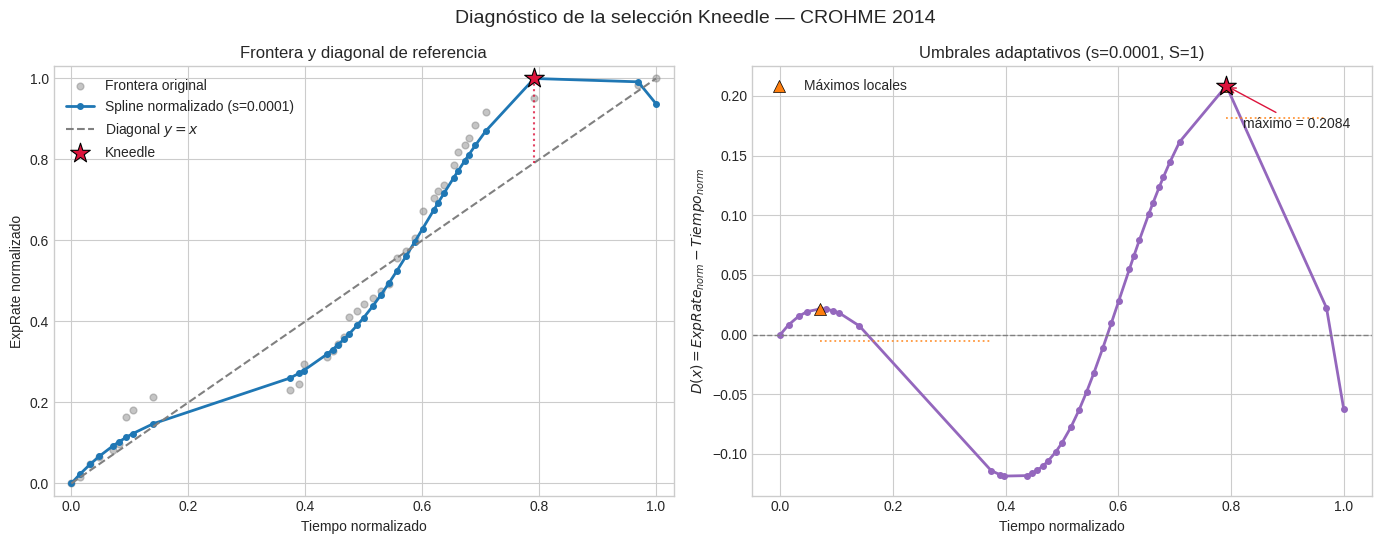

Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/diagnostico_kneedle_normalizado_crohme_2014.png


In [7]:
diagnostic = kneedle_curve.sort_values('time_normalized').reset_index(drop=True)
knee_x_norm = float(knee_point['time_normalized'])
knee_y_norm = float(knee_point['exprate_normalized'])
knee_difference = float(knee_point['kneedle_difference'])
local_maxima = diagnostic.loc[diagnostic['is_local_maximum']]
reference_diagnostics = kneedle_candidates.loc[
    np.isclose(kneedle_candidates['spline_s'], KNEEDLE_REFERENCE_SPLINE_S)
    & np.isclose(kneedle_candidates['sensitivity'], KNEEDLE_REFERENCE_S)
].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(
    diagnostic['time_normalized'], diagnostic['exprate_original_normalized'],
    s=24, alpha=0.45, color='gray', label='Frontera original',
)
axes[0].plot(
    diagnostic['time_normalized'], diagnostic['exprate_normalized'],
    marker='o', markersize=4, linewidth=2, color='#1f77b4',
    label=f'Spline normalizado (s={KNEEDLE_REFERENCE_SPLINE_S:g})',
)
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Diagonal $y=x$')
axes[0].scatter(
    [knee_x_norm], [knee_y_norm], s=220, marker='*',
    color='crimson', edgecolor='black', linewidth=0.8, zorder=5, label='Kneedle',
)
axes[0].vlines(
    knee_x_norm, knee_x_norm, knee_y_norm,
    colors='crimson', linestyles=':', alpha=0.8,
)
axes[0].set_xlabel('Tiempo normalizado')
axes[0].set_ylabel('ExpRate normalizado')
axes[0].set_title('Frontera y diagonal de referencia')
axes[0].set_xlim(-0.03, 1.03)
axes[0].set_ylim(-0.03, 1.03)
axes[0].legend()

axes[1].plot(
    diagnostic['time_normalized'], diagnostic['kneedle_difference'],
    marker='o', markersize=4, linewidth=2, color='#9467bd',
)
axes[1].axhline(0, linestyle='--', color='gray', linewidth=1)
axes[1].scatter(
    local_maxima['time_normalized'], local_maxima['kneedle_difference'],
    s=75, marker='^', color='#ff7f0e', edgecolor='black',
    linewidth=0.5, zorder=4, label='Máximos locales',
)
for candidate in reference_diagnostics.itertuples(index=False):
    start_x = float(diagnostic.iloc[int(candidate.curve_index)]['time_normalized'])
    if np.isfinite(candidate.detection_index):
        end_x = float(diagnostic.iloc[int(candidate.detection_index)]['time_normalized'])
    else:
        end_x = float(diagnostic['time_normalized'].iloc[-1])
    axes[1].hlines(
        candidate.adaptive_threshold, start_x, end_x,
        colors='#ff7f0e', linestyles=':', linewidth=1.3, alpha=0.8,
    )
axes[1].scatter(
    [knee_x_norm], [knee_difference], s=220, marker='*',
    color='crimson', edgecolor='black', linewidth=0.8, zorder=5,
)
axes[1].annotate(
    f'máximo = {knee_difference:.4f}',
    xy=(knee_x_norm, knee_difference), xytext=(12, -30),
    textcoords='offset points', arrowprops={'arrowstyle': '->', 'color': 'crimson'},
)
axes[1].set_xlabel('Tiempo normalizado')
axes[1].set_ylabel('$D(x)=ExpRate_{norm}-Tiempo_{norm}$')
axes[1].set_title(
    f'Umbrales adaptativos (s={KNEEDLE_REFERENCE_SPLINE_S:g}, '
    f'S={KNEEDLE_REFERENCE_S:g})'
)
axes[1].legend()
fig.suptitle('Diagnóstico de la selección Kneedle — CROHME 2014', fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_KNEEDLE_DIAGNOSTIC_FIG, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', OUTPUT_KNEEDLE_DIAGNOSTIC_FIG)


## Análisis de sensibilidad de Kneedle

Se comparan las 36 combinaciones de suavizado $s$ y sensibilidad $S$. Los dos primeros paneles muestran el knee principal —el confirmado con mayor diferencia normalizada cuando hay más de uno— y el tercero representa cuántos candidatos fueron confirmados para cada combinación. La ausencia de un punto significa que esa pareja $(s,S)$ no confirmó ningún knee.

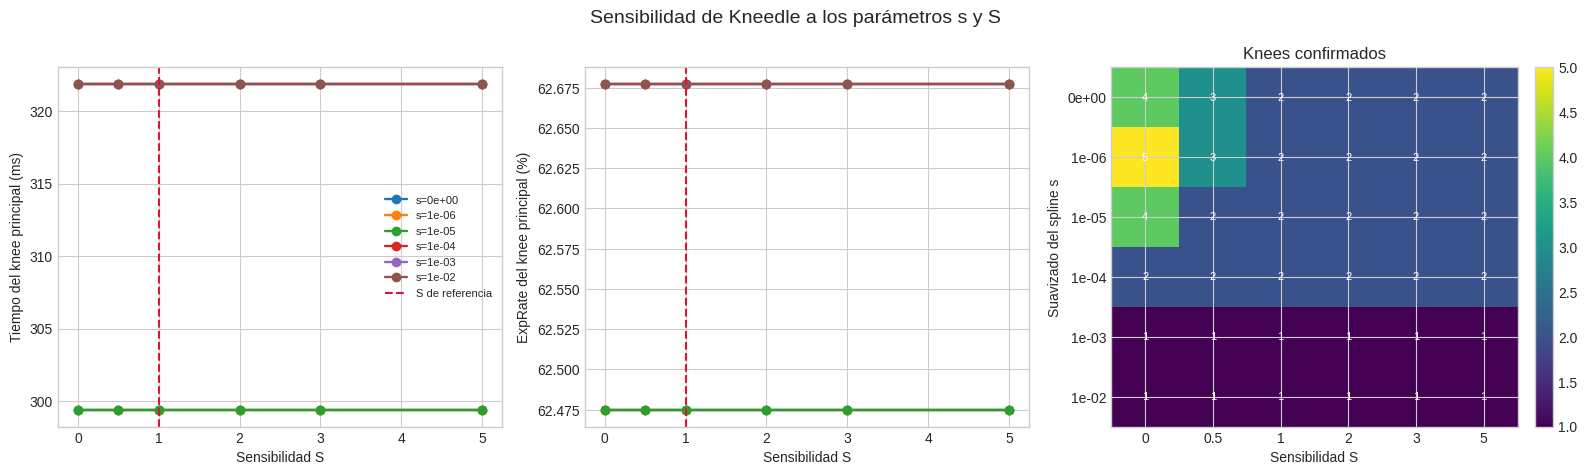

Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/sensibilidad_kneedle_s_crohme_2014.png


In [8]:
sensitivity_plot = kneedle_grid_results.sort_values(['spline_s', 'sensitivity']).copy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for spline_s, subset in sensitivity_plot.groupby('spline_s', sort=True):
    axes[0].plot(
        subset['sensitivity'], subset['average_time_ms'],
        marker='o', linewidth=1.7, label=f's={spline_s:.0e}',
    )
    axes[1].plot(
        subset['sensitivity'], subset['exprate_percent'],
        marker='o', linewidth=1.7, label=f's={spline_s:.0e}',
    )
axes[0].axvline(KNEEDLE_REFERENCE_S, color='crimson', linestyle='--', label='S de referencia')
axes[0].set_ylabel('Tiempo del knee principal (ms)')
axes[0].legend(fontsize=8)
axes[1].axvline(KNEEDLE_REFERENCE_S, color='crimson', linestyle='--')
axes[1].set_ylabel('ExpRate del knee principal (%)')

confirmed_matrix = (
    sensitivity_plot.pivot(
        index='spline_s', columns='sensitivity', values='confirmed_knees'
    )
    .reindex(index=KNEEDLE_SPLINE_S_VALUES, columns=KNEEDLE_S_VALUES)
)
image = axes[2].imshow(confirmed_matrix.to_numpy(), aspect='auto', cmap='viridis')
axes[2].set_xticks(range(len(KNEEDLE_S_VALUES)), [f'{value:g}' for value in KNEEDLE_S_VALUES])
axes[2].set_yticks(
    range(len(KNEEDLE_SPLINE_S_VALUES)),
    [f'{value:.0e}' for value in KNEEDLE_SPLINE_S_VALUES],
)
axes[2].set_xlabel('Sensibilidad S')
axes[2].set_ylabel('Suavizado del spline s')
axes[2].set_title('Knees confirmados')
for row in range(confirmed_matrix.shape[0]):
    for column in range(confirmed_matrix.shape[1]):
        axes[2].text(
            column, row, f'{int(confirmed_matrix.iloc[row, column])}',
            ha='center', va='center', color='white', fontsize=8,
        )
fig.colorbar(image, ax=axes[2], fraction=0.046, pad=0.04)
axes[0].set_xlabel('Sensibilidad S')
axes[1].set_xlabel('Sensibilidad S')
fig.suptitle('Sensibilidad de Kneedle a los parámetros s y S', fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_KNEEDLE_SENSITIVITY_FIG, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', OUTPUT_KNEEDLE_SENSITIVITY_FIG)


## Visualización del compromiso reconocimiento–tiempo

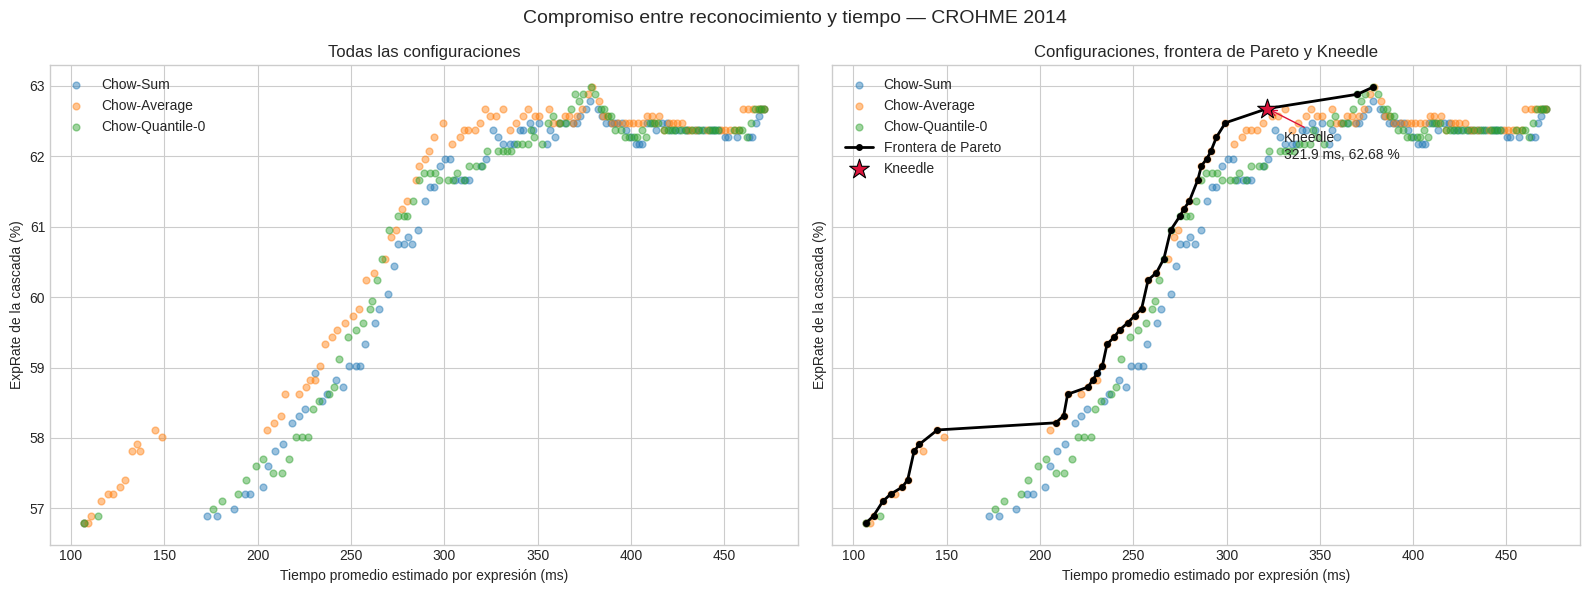

Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/pareto_kneedle_derivacion_crohme_2014.png


In [9]:
colors = {
    'Chow-Sum': '#1f77b4',
    'Chow-Average': '#ff7f0e',
    'Chow-Quantile-0': '#2ca02c',
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
for axis in axes:
    for label, subset in configurations.groupby('metric_label', sort=False):
        axis.scatter(
            subset['average_time_ms'], 100 * subset['exprate'],
            s=24, alpha=0.45, color=colors[label], label=label,
        )
    axis.set_xlabel('Tiempo promedio estimado por expresión (ms)')
    axis.set_ylabel('ExpRate de la cascada (%)')
    axis.legend()

frontier_points = kneedle_curve.sort_values('average_time_ms')
axes[1].plot(
    frontier_points['average_time_ms'], 100 * frontier_points['exprate'],
    color='black', linewidth=2.0, marker='o', markersize=4, label='Frontera de Pareto',
)
axes[1].scatter(
    [knee_time], [100 * knee_exprate], s=220, marker='*',
    color='crimson', edgecolor='black', linewidth=0.8, zorder=5, label='Kneedle',
)
axes[1].annotate(
    f'Kneedle\n{knee_time:.1f} ms, {100 * knee_exprate:.2f} %',
    xy=(knee_time, 100 * knee_exprate), xytext=(12, -36),
    textcoords='offset points', arrowprops={'arrowstyle': '->', 'color': 'crimson'},
)
axes[0].set_title('Todas las configuraciones')
axes[1].set_title('Configuraciones, frontera de Pareto y Kneedle')
axes[1].legend()
fig.suptitle('Compromiso entre reconocimiento y tiempo — CROHME 2014', fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_PARETO_FIG, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', OUTPUT_PARETO_FIG)


## ExpRate y tasa de escalamiento por percentil

Esta vista permite comprobar la dirección del enrutamiento: al aumentar el percentil, el umbral se vuelve más exigente y normalmente aumenta la proporción derivada.

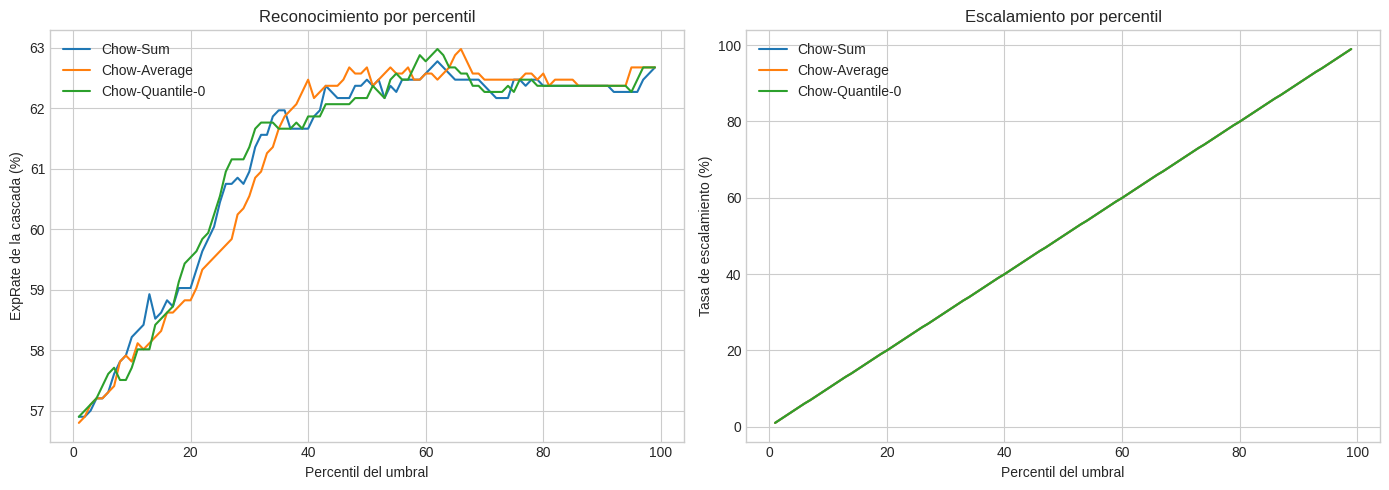

Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/exprate_escalamiento_derivacion_crohme_2014.png


In [10]:
percentile_configs = configurations.loc[configurations['policy'].eq('percentile')].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for label, subset in percentile_configs.groupby('metric_label', sort=False):
    subset = subset.sort_values('percentile')
    axes[0].plot(subset['percentile'], subset['exprate_percent'], label=label, color=colors[label])
    axes[1].plot(
        subset['percentile'], subset['escalation_rate_percent'],
        label=label, color=colors[label],
    )
axes[0].set_ylabel('ExpRate de la cascada (%)')
axes[1].set_ylabel('Tasa de escalamiento (%)')
for axis in axes:
    axis.set_xlabel('Percentil del umbral')
    axis.legend()
axes[0].set_title('Reconocimiento por percentil')
axes[1].set_title('Escalamiento por percentil')
fig.tight_layout()
fig.savefig(OUTPUT_RATES_FIG, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', OUTPUT_RATES_FIG)


## Tiempo promedio estimado por percentil

Esta gráfica complementa las curvas de ExpRate y escalamiento mostrando directamente cómo aumenta el costo temporal al hacer más exigente el umbral de cada medidor.

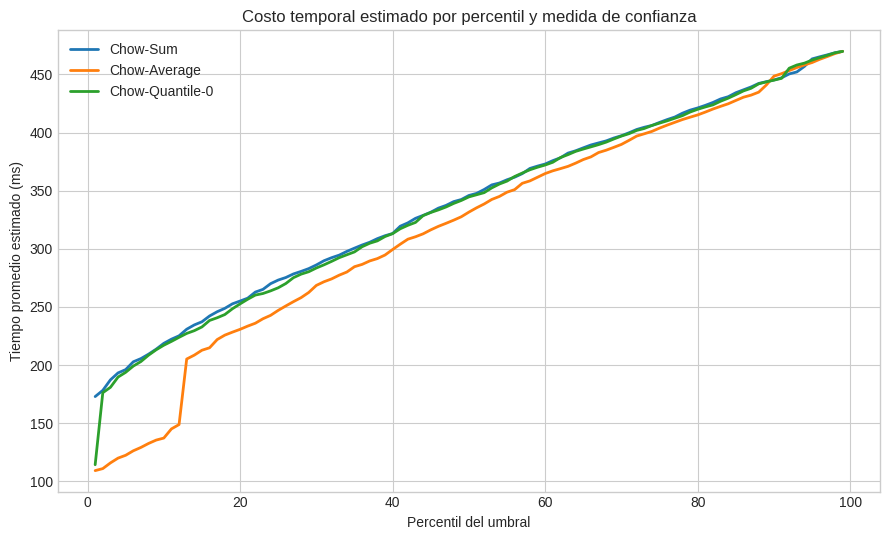

Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/tiempo_percentil_derivacion_crohme_2014.png


In [11]:
fig, axis = plt.subplots(figsize=(9, 5.5))
for label, subset in percentile_configs.groupby('metric_label', sort=False):
    subset = subset.sort_values('percentile')
    axis.plot(
        subset['percentile'], subset['average_time_ms'],
        linewidth=2, label=label, color=colors[label],
    )
axis.set_xlabel('Percentil del umbral')
axis.set_ylabel('Tiempo promedio estimado (ms)')
axis.set_title('Costo temporal estimado por percentil y medida de confianza')
axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT_TIME_PERCENTILE_FIG, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', OUTPUT_TIME_PERCENTILE_FIG)


## Estabilidad local alrededor del punto Kneedle

Se muestran las once configuraciones de la misma medida con tasa de escalamiento más cercana a la configuración Kneedle. Una región relativamente plana indica que pequeñas variaciones del umbral producen cambios limitados; una pendiente pronunciada revela mayor sensibilidad.

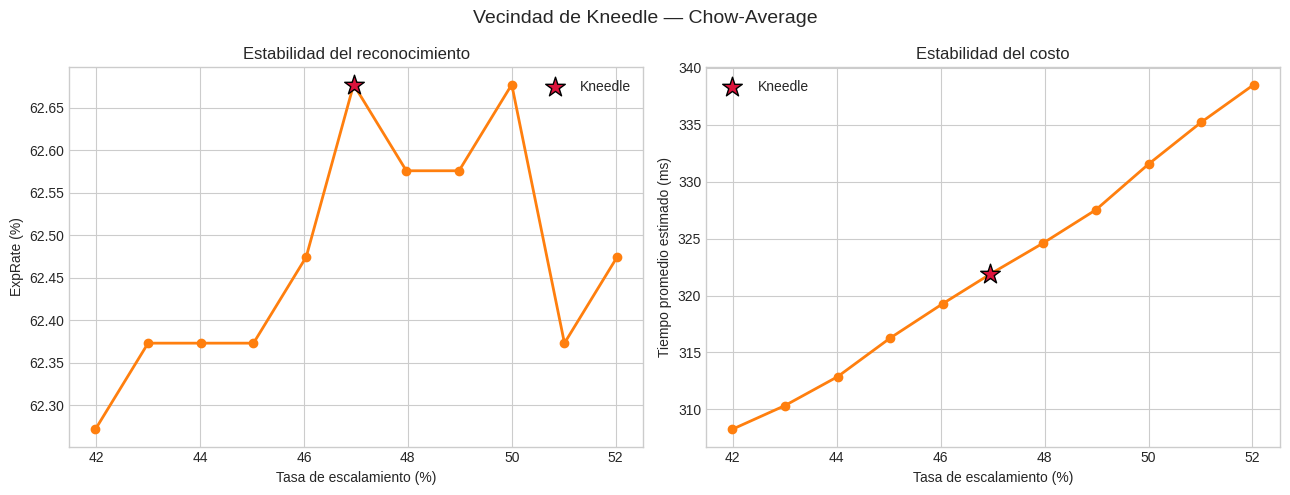

,configuration_id,metric_label,policy,percentile,threshold,escalation_rate_percent,exprate_percent,average_time_ms
143,c144,Chow-Average,percentile,42,-0.02146990,41.99,62.272,308.250
144,c145,Chow-Average,percentile,43,-0.01912099,43.00,62.373,310.334
145,c146,Chow-Average,percentile,44,-0.01740484,44.02,62.373,312.870
146,c147,Chow-Average,percentile,45,-0.01633737,45.03,62.373,316.271
147,c148,Chow-Average,percentile,46,-0.01496752,46.04,62.475,319.294
148,c149,Chow-Average,percentile,47,-0.01338814,46.96,62.677,321.890
149,c150,Chow-Average,percentile,48,-0.01230677,47.97,62.576,324.600
150,c151,Chow-Average,percentile,49,-0.01124176,48.99,62.576,327.520
151,c152,Chow-Average,percentile,50,-0.00964632,50.00,62.677,331.534
152,c153,Chow-Average,percentile,51,-0.00863007,51.01,62.373,335.214


Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/estabilidad_local_kneedle_crohme_2014.png


In [12]:
knee_choice = (
    knee_configurations.sort_values(
        ['escalation_rate', 'metric_label', 'percentile'], na_position='last'
    ).iloc[0]
)
knee_escalation_percent = float(knee_choice['escalation_rate_percent'])
local_stability = configurations.loc[
    configurations['metric'].eq(knee_choice['metric'])
].copy()
local_stability['distance_to_knee'] = (
    local_stability['escalation_rate_percent'] - knee_escalation_percent
).abs()
local_stability = (
    local_stability.nsmallest(11, 'distance_to_knee')
    .sort_values('escalation_rate_percent')
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(
    local_stability['escalation_rate_percent'], local_stability['exprate_percent'],
    marker='o', linewidth=2, color=colors[knee_choice['metric_label']],
)
axes[0].scatter(
    [knee_escalation_percent], [knee_choice['exprate_percent']],
    marker='*', s=220, color='crimson', edgecolor='black', zorder=5, label='Kneedle',
)
axes[0].set_ylabel('ExpRate (%)')
axes[0].set_title('Estabilidad del reconocimiento')
axes[0].legend()

axes[1].plot(
    local_stability['escalation_rate_percent'], local_stability['average_time_ms'],
    marker='o', linewidth=2, color=colors[knee_choice['metric_label']],
)
axes[1].scatter(
    [knee_escalation_percent], [knee_choice['average_time_ms']],
    marker='*', s=220, color='crimson', edgecolor='black', zorder=5, label='Kneedle',
)
axes[1].set_ylabel('Tiempo promedio estimado (ms)')
axes[1].set_title('Estabilidad del costo')
axes[1].legend()
for axis in axes:
    axis.set_xlabel('Tasa de escalamiento (%)')
fig.suptitle(f'Vecindad de Kneedle — {knee_choice["metric_label"]}', fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_STABILITY_FIG, dpi=180, bbox_inches='tight')
plt.show()
display(local_stability[[
    'configuration_id', 'metric_label', 'policy', 'percentile', 'threshold',
    'escalation_rate_percent', 'exprate_percent', 'average_time_ms',
]].style.format({
    'percentile': '{:.0f}', 'threshold': '{:.8f}',
    'escalation_rate_percent': '{:.2f}', 'exprate_percent': '{:.3f}',
    'average_time_ms': '{:.3f}',
}, na_rep='—'))
print('Gráfica:', OUTPUT_STABILITY_FIG)


## Ganancias y pérdidas producidas por la derivación

Una expresión se **recupera** cuando SANv2 falla y PosFormer acierta después de derivarla. Se considera **pérdida** cuando SANv2 acertaba pero PosFormer falla. La diferencia entre ambos conteos es la ganancia neta respecto de usar SANv2 en todas las muestras.

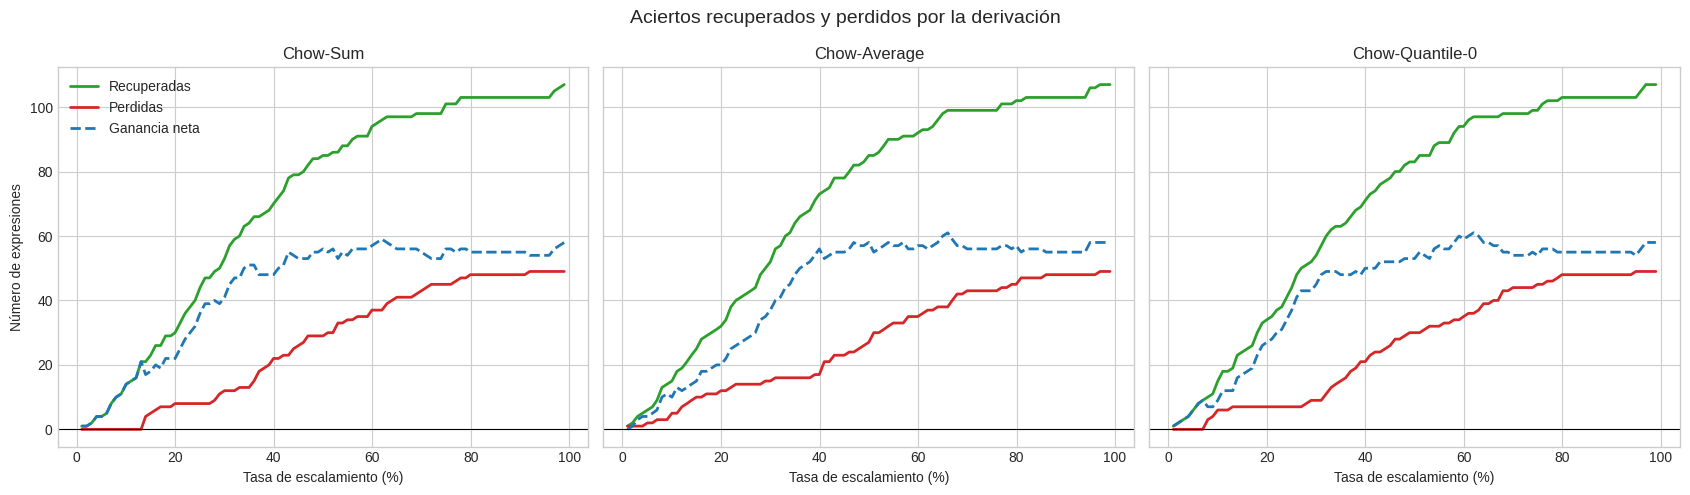

Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/ganancias_perdidas_derivacion_crohme_2014.png


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for axis, (label, subset) in zip(axes, percentile_configs.groupby('metric_label', sort=False)):
    subset = subset.sort_values('escalation_rate_percent')
    axis.plot(
        subset['escalation_rate_percent'], subset['recovered_count'],
        color='#2ca02c', linewidth=2, label='Recuperadas',
    )
    axis.plot(
        subset['escalation_rate_percent'], subset['lost_count'],
        color='#d62728', linewidth=2, label='Perdidas',
    )
    axis.plot(
        subset['escalation_rate_percent'], subset['net_gain_count'],
        color='#1f77b4', linewidth=2, linestyle='--', label='Ganancia neta',
    )
    axis.axhline(0, color='black', linewidth=0.8)
    axis.set_title(label)
    axis.set_xlabel('Tasa de escalamiento (%)')
axes[0].set_ylabel('Número de expresiones')
axes[0].legend()
fig.suptitle('Aciertos recuperados y perdidos por la derivación', fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_GAIN_LOSS_FIG, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', OUTPUT_GAIN_LOSS_FIG)


## Composición acumulada del resultado final

Cada configuración divide el conjunto en cuatro grupos excluyentes: aceptadas correctas, aceptadas incorrectas, derivadas correctas y derivadas incorrectas. La gráfica apilada permite observar cómo cambia la procedencia de los aciertos y errores al aumentar el escalamiento.

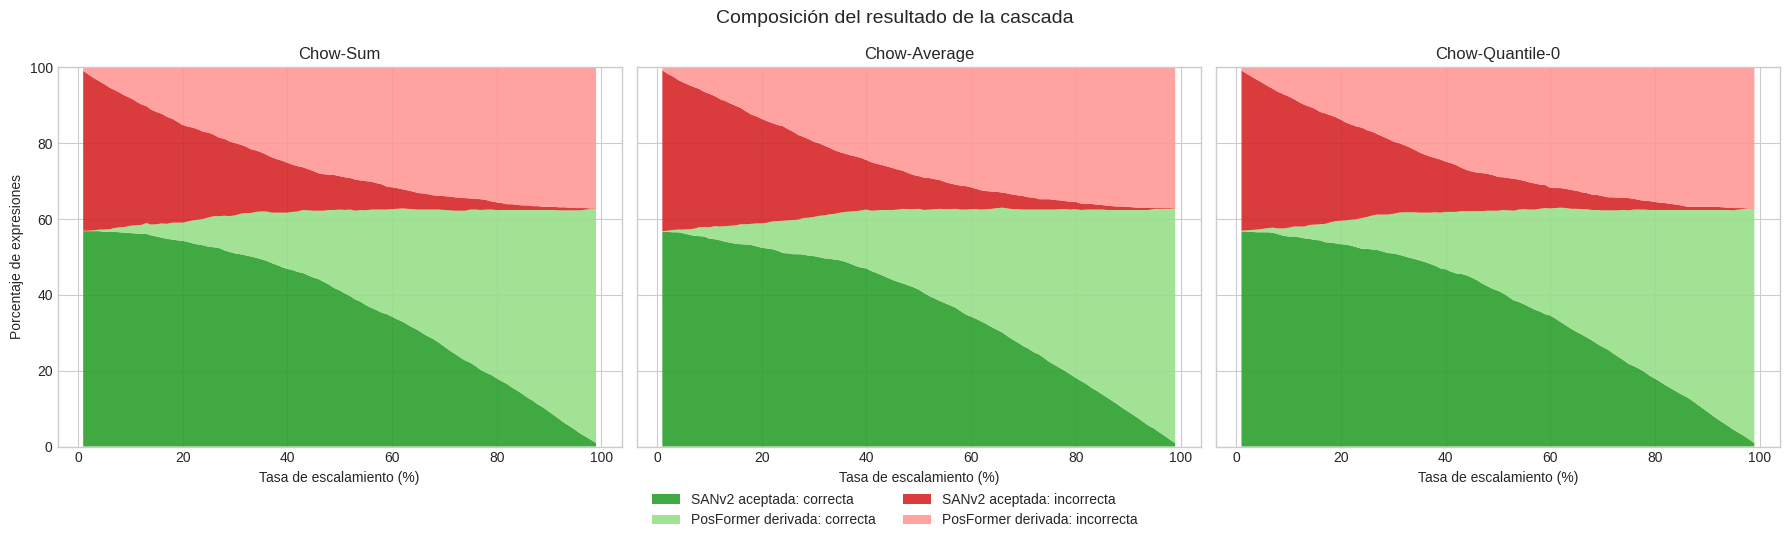

Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/composicion_resultados_derivacion_crohme_2014.png


In [14]:
composition_columns = [
    'accepted_correct_count', 'escalated_correct_count',
    'accepted_wrong_count', 'escalated_wrong_count',
]
composition_labels = [
    'SANv2 aceptada: correcta', 'PosFormer derivada: correcta',
    'SANv2 aceptada: incorrecta', 'PosFormer derivada: incorrecta',
]
composition_colors = ['#2ca02c', '#98df8a', '#d62728', '#ff9896']

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for axis, (label, subset) in zip(axes, percentile_configs.groupby('metric_label', sort=False)):
    subset = subset.sort_values('escalation_rate_percent')
    percentages = [100 * subset[column].to_numpy() / len(data) for column in composition_columns]
    axis.stackplot(
        subset['escalation_rate_percent'], *percentages,
        labels=composition_labels, colors=composition_colors, alpha=0.9,
    )
    axis.set_title(label)
    axis.set_xlabel('Tasa de escalamiento (%)')
    axis.set_ylim(0, 100)
axes[0].set_ylabel('Porcentaje de expresiones')
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Composición del resultado de la cascada', fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_COMPOSITION_FIG, dpi=180, bbox_inches='tight')
plt.show()
print('Gráfica:', OUTPUT_COMPOSITION_FIG)


## Costo marginal sobre la frontera de Pareto

Para cada transición entre puntos consecutivos de la frontera se calcula la ganancia de ExpRate en puntos porcentuales por cada 100 ms adicionales. Esta razón muestra dónde el rendimiento adicional comienza a requerir incrementos desproporcionados de tiempo.

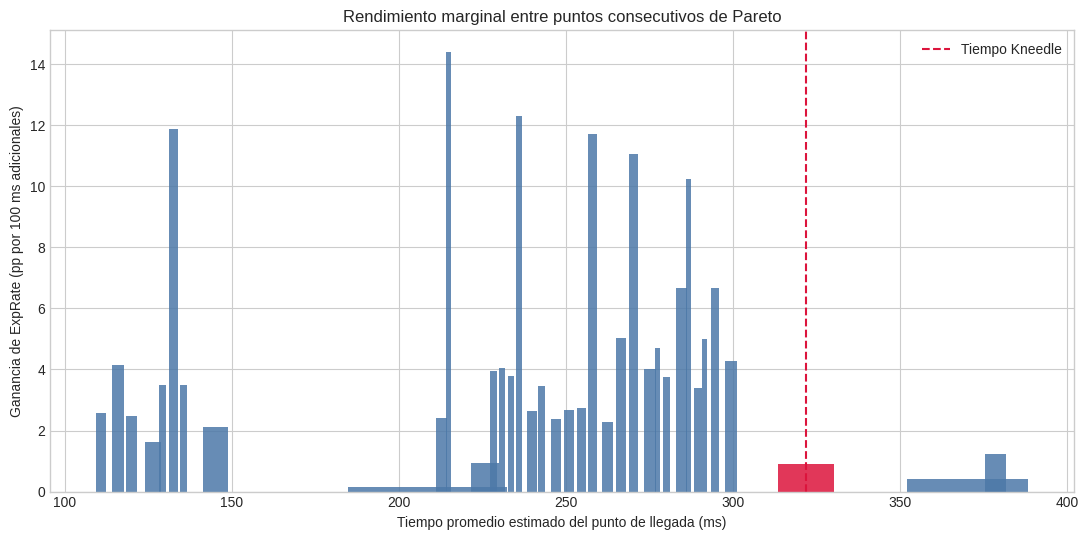

,average_time_ms,exprate,delta_time_ms,delta_exprate_pp,exprate_pp_per_100_ms
1,110.913,0.56897,3.959,0.1014,2.5615
2,115.808,0.57099,4.894,0.2028,4.1445
3,119.932,0.57201,4.124,0.1014,2.4593
4,126.232,0.57302,6.300,0.1014,1.6098
5,129.126,0.57404,2.895,0.1014,3.5038
6,132.543,0.57809,3.416,0.4057,11.8750
7,135.445,0.57911,2.902,0.1014,3.4947
8,145.065,0.58114,9.620,0.2028,2.1085
9,208.529,0.58215,63.464,0.1014,0.1598
10,212.731,0.58316,4.203,0.1014,2.4132


Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/costo_marginal_pareto_crohme_2014.png


In [15]:
marginal = kneedle_curve.sort_values('average_time_ms').reset_index(drop=True).copy()
marginal['delta_time_ms'] = marginal['average_time_ms'].diff()
marginal['delta_exprate_pp'] = 100 * marginal['exprate'].diff()
marginal['exprate_pp_per_100_ms'] = (
    marginal['delta_exprate_pp'] / marginal['delta_time_ms'] * 100
)
marginal_valid = marginal.loc[
    marginal['delta_time_ms'].gt(0) & np.isfinite(marginal['exprate_pp_per_100_ms'])
].copy()
bar_colors = np.where(
    np.isclose(marginal_valid['average_time_ms'], knee_time, rtol=1e-10, atol=1e-10),
    'crimson', '#4c78a8',
)

fig, axis = plt.subplots(figsize=(11, 5.5))
axis.bar(
    marginal_valid['average_time_ms'], marginal_valid['exprate_pp_per_100_ms'],
    width=np.maximum(marginal_valid['delta_time_ms'] * 0.75, 1.0),
    color=bar_colors, alpha=0.85,
)
axis.axvline(knee_time, color='crimson', linestyle='--', linewidth=1.5, label='Tiempo Kneedle')
axis.set_xlabel('Tiempo promedio estimado del punto de llegada (ms)')
axis.set_ylabel('Ganancia de ExpRate (pp por 100 ms adicionales)')
axis.set_title('Rendimiento marginal entre puntos consecutivos de Pareto')
axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT_MARGINAL_FIG, dpi=180, bbox_inches='tight')
plt.show()
display(marginal_valid[[
    'average_time_ms', 'exprate', 'delta_time_ms',
    'delta_exprate_pp', 'exprate_pp_per_100_ms',
]].style.format({
    'average_time_ms': '{:.3f}', 'exprate': '{:.5f}',
    'delta_time_ms': '{:.3f}', 'delta_exprate_pp': '{:.4f}',
    'exprate_pp_per_100_ms': '{:.4f}',
}))
print('Gráfica:', OUTPUT_MARGINAL_FIG)


## Exportación reproducible

Se exportan todas las configuraciones, la frontera no dominada, la configuración o configuraciones equivalentes del punto Kneedle y un resumen JSON. Los archivos se escriben únicamente al ejecutar esta celda.

In [16]:
configurations.to_csv(OUTPUT_CONFIGS, index=False, encoding='utf-8')
pareto.to_csv(OUTPUT_PARETO, index=False, encoding='utf-8')
knee_configurations.to_csv(OUTPUT_KNEE, index=False, encoding='utf-8')
kneedle_candidates.to_csv(OUTPUT_KNEEDLE_CANDIDATES, index=False, encoding='utf-8')
kneedle_grid_results.to_csv(OUTPUT_KNEEDLE_GRID, index=False, encoding='utf-8')

summary = {
    'dataset': 'CROHME 2014',
    'role': 'experimentación y selección de configuración',
    'samples': int(len(data)),
    'light_model': 'SANv2',
    'heavy_model': 'PosFormer',
    'normalization': 'Espacios normalizados y eliminación del token \\limits',
    'threshold_rule': 'Aceptar SANv2 si score >= threshold; derivar si score < threshold',
    'candidate_percentiles': [int(value) for value in PERCENTILES],
    'extreme_cases': ['accept_all', 'escalate_all'],
    'metrics': list(METRICS.keys()),
    'configuration_count': int(len(configurations)),
    'pareto_configuration_count': int(len(pareto)),
    'pareto_unique_objective_points': int(len(kneedle_curve)),
    'baselines': {
        'sanv2_exprate_percent': float(100 * data['sanv2_correct'].mean()),
        'posformer_exprate_percent': float(100 * data['posformer_correct'].mean()),
        'sanv2_average_time_ms': float(data['sanv2_time_ms'].mean()),
        'posformer_average_time_ms': float(data['posformer_time_ms'].mean()),
    },
    'kneedle': {
        'method': (
            'Kneedle offline: smoothing spline, normalización min-max, máximos locales, '
            'umbral adaptativo y confirmación/reinicio'
        ),
        'smoothing': {
            'method': 'scipy.interpolate.UnivariateSpline',
            'tested_s_values': [float(value) for value in KNEEDLE_SPLINE_S_VALUES],
            'reference_s': float(KNEEDLE_REFERENCE_SPLINE_S),
        },
        'tested_sensitivity_values': [float(value) for value in KNEEDLE_S_VALUES],
        'reference_sensitivity': float(KNEEDLE_REFERENCE_S),
        'primary_knee_rule': (
            'Entre los knees confirmados para cada combinación (s, S), seleccionar el de mayor diferencia normalizada'
        ),
        'grid_size': int(len(kneedle_grid_results)),
        'confirmed_knees_by_combination': [
            {
                'spline_s': float(row.spline_s),
                'sensitivity': float(row.sensitivity),
                'confirmed_knees': int(row.confirmed_knees),
            }
            for row in kneedle_grid_results.itertuples(index=False)
        ],
        'average_time_ms': knee_time,
        'exprate_percent': float(100 * knee_exprate),
        'difference': float(knee_point['kneedle_difference']),
        'adaptive_threshold': float(reference_candidate['adaptive_threshold']),
        'curve_index': int(reference_candidate['curve_index']),
        'configuration_ids': knee_configurations['configuration_id'].tolist(),
    },
    'timing_note': (
        'Estimación por muestra: tiempo SANv2 más tiempo PosFormer únicamente al derivar; '
        'los tiempos proceden de ejecuciones registradas previamente.'
    ),
}
with OUTPUT_SUMMARY.open('w', encoding='utf-8') as stream:
    json.dump(summary, stream, ensure_ascii=False, indent=2)

print('Configuraciones:', OUTPUT_CONFIGS)
print('Frontera de Pareto:', OUTPUT_PARETO)
print('Selección Kneedle:', OUTPUT_KNEE)
print('Candidatos Kneedle por combinación:', OUTPUT_KNEEDLE_CANDIDATES)
print('Tabla completa s × S:', OUTPUT_KNEEDLE_GRID)
print('Resumen:', OUTPUT_SUMMARY)


Configuraciones: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/configuraciones_derivacion_crohme_2014.csv
Frontera de Pareto: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/frontera_pareto_derivacion_crohme_2014.csv
Selección Kneedle: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/configuracion_kneedle_crohme_2014.csv
Candidatos Kneedle por combinación: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/candidatos_kneedle_spline_s_sensibilidad_crohme_2014.csv
Tabla completa s × S: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_analisis/resultados/resultados_kneedle_spline_s_sensibilidad_crohme_2014.csv
Resumen: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/03_anali

## Criterio para la siguiente etapa

La configuración Kneedle obtenida en CROHME 2014 debe congelarse —medida, umbral y regla de comparación incluidos— antes de evaluar CROHME 2016 y 2019. No deben recalcularse percentiles ni reajustarse el umbral con esos conjuntos de prueba.

También conviene reportar junto al punto de rodilla: la frontera completa, los extremos de aceptación/derivación total, la tasa de escalamiento y la advertencia de que los tiempos son estimaciones basadas en mediciones previas por modelo.